# Explainable AI for Warfarin Dose Prediction Using SHAP and Template-Based NLG

This notebook is designed as a **direct explanation layer** for the final clinical–genetic Ridge Regression pipeline reported in the comparative warfarin dose-prediction study.

**What it does**
1. Loads `IWPS.csv` and prepares the same clinical-only and clinical-genetic feature sets.
2. Applies the same 80/20 split and preprocessing approach as the research study.
3. Fits the final tuned models using the same hyperparameter settings reported in the research paper.
4. Explains the final clinical–genetic Ridge pipeline using model-agnostic Kernel SHAP.
5. Generates template-based natural-language explanations from SHAP values.
6. Saves plots, tables, explanations, and a Word report in `xai_results/`.

**Research-only notice:** This workflow is for academic research. It does not establish causation, clinical safety, or treatment suitability. It must not be used to prescribe or adjust warfarin treatment for a real patient.

**Required file:** Place `IWPS.csv` in the same folder as this notebook before running.

In [1]:
%pip install python-docx shap

import os, re, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import shap

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "IWPS.csv"
OUTPUT_DIR = "xai_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("SHAP version:", shap.__version__)
print("scikit-learn version:", sklearn.__version__)

Note: you may need to restart the kernel to use updated packages.
SHAP version: 0.52.0
scikit-learn version: 1.7.2


## 1. Load dataset and define features

The target is the recorded therapeutic weekly warfarin dose, measured in mg/week. Records with missing, non-numeric, zero, or negative target values are excluded from modelling.

The clinical-only configuration uses 15 predictors. The clinical-genetic configuration adds `CYP2C9 genotypes` and `VKORC1 -1639 consensus`, giving 17 predictors before categorical encoding.

In [2]:
df = pd.read_csv(DATA_PATH)

# Remove columns that contain no values at all.
df = df.drop(columns=df.columns[df.isna().all()])

target = "Therapeutic Dose of Warfarin"
df["dose"] = pd.to_numeric(df[target], errors="coerce")
df_model = df[df["dose"].notna() & (df["dose"] > 0)].copy()

print("Original dataset shape:", df.shape)
print("Rows with a valid positive target:", len(df_model))
display(df_model["dose"].describe())

clinical_features = [
    "Gender", "Race (Reported)", "Age", "Height (cm)", "Weight (kg)",
    "Indication for Warfarin Treatment", "Diabetes",
    "Congestive Heart Failure and/or Cardiomyopathy", "Valve Replacement",
    "Target INR", "Current Smoker", "Amiodarone (Cordarone)",
    "Carbamazepine (Tegretol)", "Phenytoin (Dilantin)",
    "Rifampin or Rifampicin"
]

genetic_features = ["Cyp2C9 genotypes", "VKORC1 -1639 consensus"]

required_columns = clinical_features + genetic_features + [target]
missing_columns = [c for c in required_columns if c not in df_model.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

y = df_model["dose"]
X_clinical = df_model[clinical_features].copy()
X_genetic = df_model[clinical_features + genetic_features].copy()

numeric_features = ["Height (cm)", "Weight (kg)"]

for frame in [X_clinical, X_genetic]:
    for col in frame.columns:
        if col not in numeric_features:
            frame[col] = frame[col].apply(
                lambda value: str(value) if pd.notna(value) else np.nan
            )

print("Clinical-only predictors:", len(clinical_features))
print("Clinical-genetic predictors before encoding:", len(clinical_features + genetic_features))

Original dataset shape: (6161, 69)
Rows with a valid positive target: 5528


count    5528.000000
mean       30.977873
std        16.801040
min         2.100000
25%        19.530000
50%        28.000000
75%        38.500000
max       315.000000
Name: dose, dtype: float64

Clinical-only predictors: 15
Clinical-genetic predictors before encoding: 17


## 2. Train-test split and preprocessing

The same record indices and random seed are used for both feature configurations. Height and weight are treated as numerical predictors; all other predictors, including age and target INR, are treated as categorical predictors.

Preprocessing is contained in a `Pipeline`. During cross-validation, imputation and encoding are fitted within each training fold and applied to the corresponding validation fold. For final evaluation, preprocessing is fitted on the complete training set and applied to the held-out test set. This avoids leakage from validation or test data into preprocessing statistics.

In [3]:
train_idx, test_idx = train_test_split(
    X_clinical.index,
    test_size=0.20,
    random_state=RANDOM_STATE
)

X_clinical_train, X_clinical_test = X_clinical.loc[train_idx], X_clinical.loc[test_idx]
X_genetic_train, X_genetic_test = X_genetic.loc[train_idx], X_genetic.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Training records:", len(train_idx))
print("Test records:", len(test_idx))

def make_preprocessor(features):
    categorical_features = [c for c in features if c not in numeric_features]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

preprocessor_clinical = make_preprocessor(clinical_features)
preprocessor_genetic = make_preprocessor(clinical_features + genetic_features)

Training records: 4422
Test records: 1106


## 3. Fit the final research models

To align this explanation workflow with the final comparative study, the tuned hyperparameter settings reported in the research paper are used directly:

- Ridge: `alpha = 10`
- Lasso: `alpha = 0.01`, `max_iter = 20000`
- Random Forest: 400 trees, maximum depth 10, random state 42
- Minimum samples per leaf: 10 for clinical-only and 5 for clinical-genetic

Linear Regression is used without hyperparameter tuning.

`clone()` is used for every pipeline component. This ensures that each feature configuration receives independent fitted preprocessing and model objects rather than reusing the same estimator object.

In [4]:
def make_final_models(min_samples_leaf):
    return {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=10.0),
        "Lasso Regression": Lasso(alpha=0.01, max_iter=20000),
        "Random Forest Regression": RandomForestRegressor(
            n_estimators=400,
            max_depth=10,
            min_samples_leaf=min_samples_leaf,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    }

final_models_clinical = make_final_models(min_samples_leaf=10)
final_models_genetic = make_final_models(min_samples_leaf=5)

feature_configurations = {
    "Clinical-only": (
        preprocessor_clinical,
        X_clinical_train, X_clinical_test,
        final_models_clinical
    ),
    "Clinical-genetic": (
        preprocessor_genetic,
        X_genetic_train, X_genetic_test,
        final_models_genetic
    )
}

final_results = []
final_pipelines = {}
final_predictions = {}

for configuration, (preprocessor, X_train, X_test, models) in feature_configurations.items():
    for model_name, model in models.items():
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ])

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        final_pipelines[(configuration, model_name)] = pipeline
        final_predictions[(configuration, model_name)] = predictions

        final_results.append({
            "Feature configuration": configuration,
            "Model": model_name,
            "MAE (mg/week)": mean_absolute_error(y_test, predictions),
            "RMSE (mg/week)": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions),
            "Within 20% (%)": np.mean(
                (predictions >= 0.8 * y_test) & (predictions <= 1.2 * y_test)
            ) * 100
        })

final_results_df = pd.DataFrame(final_results)
display(final_results_df)
final_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_model_comparison.csv"),
    index=False
)

# The explained model is the final clinical-genetic Ridge pipeline from the research study.
explained_configuration = "Clinical-genetic"
explained_model_name = "Ridge Regression"
explained_pipeline = final_pipelines[(explained_configuration, explained_model_name)]
explained_predictions = final_predictions[(explained_configuration, explained_model_name)]

explained_row = final_results_df[
    (final_results_df["Feature configuration"] == explained_configuration) &
    (final_results_df["Model"] == explained_model_name)
].iloc[0]

print("Explained final pipeline:", explained_configuration, "-", explained_model_name)
display(explained_row.to_frame("Value"))

,Feature configuration,Model,MAE (mg/week),RMSE (mg/week),R2,Within 20% (%)
0,Clinical-only,Linear Regression,9.871389,13.380244,0.268331,37.974684
1,Clinical-only,Ridge Regression,9.745460,13.144361,0.293901,38.245931
2,Clinical-only,Lasso Regression,9.748970,13.200273,0.287881,39.059675
3,Clinical-only,Random Forest Regression,9.852274,13.280912,0.279154,38.155515
4,Clinical-genetic,Linear Regression,8.560209,11.851899,0.425933,44.122966
5,Clinical-genetic,Ridge Regression,8.467438,11.621569,0.448029,45.117541
6,Clinical-genetic,Lasso Regression,8.484325,11.710939,0.439507,44.755877
7,Clinical-genetic,Random Forest Regression,8.775796,12.116514,0.400012,43.490054


Explained final pipeline: Clinical-genetic - Ridge Regression


,Value
Feature configuration,Clinical-genetic
Model,Ridge Regression
MAE (mg/week),8.467438
RMSE (mg/week),11.621569
R2,0.448029
Within 20% (%),45.117541


## 4. SHAP explanation setup

The final clinical-genetic Ridge pipeline is explained using `shap.KernelExplainer`. This is a model-agnostic Kernel SHAP approach, not a Permutation Explainer.

The explainer receives the original human-readable input columns and calls the complete preprocessing-plus-Ridge pipeline. A small random background sample from the training set and a small random sample from the held-out test set are used to keep runtime manageable.

These explanations describe the fitted model on the selected explanation sample. They are not causal effects and are not patient-specific dosing advice.

In [6]:
X_explain_raw = X_genetic_test.sample(
    n=min(20, len(X_genetic_test)),
    random_state=RANDOM_STATE
).copy()

background_raw = X_genetic_train.sample(
    n=min(30, len(X_genetic_train)),
    random_state=RANDOM_STATE
).copy()

feature_names = clinical_features + genetic_features

def predict_from_raw_dataframe(data):
    if isinstance(data, pd.DataFrame):
        frame = data.copy()
    else:
        frame = pd.DataFrame(data, columns=feature_names)
    return explained_pipeline.predict(frame)

kernel_explainer = shap.KernelExplainer(
    predict_from_raw_dataframe,
    background_raw.to_numpy()
)

shap_values_array = kernel_explainer.shap_values(
    X_explain_raw.to_numpy(),
    nsamples=100
)

if isinstance(shap_values_array, list):
    shap_values_array = shap_values_array[0]

shap_values_array = np.asarray(shap_values_array)

shap_values = shap.Explanation(
    values=shap_values_array,
    base_values=np.repeat(
        np.asarray(kernel_explainer.expected_value).mean(),
        len(X_explain_raw)
    ),
    data=X_explain_raw.to_numpy(),
    feature_names=feature_names
)

print("SHAP values shape:", shap_values_array.shape)
print("Background records:", len(background_raw))
print("Explained test records:", len(X_explain_raw))
print("SHAP samples per explanation:", 100)

  0%|          | 0/20 [00:00<?, ?it/s]

SHAP values shape: (20, 17)
Background records: 30
Explained test records: 20
SHAP samples per explanation: 100


## 5. Verify SHAP additivity

For each explained record, the baseline prediction plus the sum of all SHAP contributions should approximately equal the model prediction. This check verifies the internal consistency of the SHAP output; it does not verify clinical correctness or explanation stability.

In [7]:
reconstructed_predictions = (
    np.asarray(shap_values.base_values)
    + shap_values_array.sum(axis=1)
)

pipeline_predictions = explained_pipeline.predict(X_explain_raw)

max_absolute_difference = np.max(np.abs(reconstructed_predictions - pipeline_predictions))

print("Maximum absolute additivity difference:", max_absolute_difference)

additivity_check = pd.DataFrame({
    "SHAP baseline": shap_values.base_values,
    "Sum of SHAP values": shap_values_array.sum(axis=1),
    "Reconstructed prediction": reconstructed_predictions,
    "Pipeline prediction": pipeline_predictions,
    "Absolute difference": np.abs(reconstructed_predictions - pipeline_predictions)
})

display(additivity_check)
additivity_check.to_csv(
    os.path.join(OUTPUT_DIR, "shap_additivity_check.csv"),
    index=False
)

Maximum absolute additivity difference: 7.105427357601002e-15


,SHAP baseline,Sum of SHAP values,Reconstructed prediction,Pipeline prediction,Absolute difference
0,29.953385,-0.301090,29.652295,29.652295,0.000000e+00
1,29.953385,19.439955,49.393340,49.393340,0.000000e+00
2,29.953385,20.781888,50.735272,50.735272,7.105427e-15
3,29.953385,11.691644,41.645029,41.645029,0.000000e+00
4,29.953385,8.411407,38.364792,38.364792,0.000000e+00
5,29.953385,-2.660255,27.293130,27.293130,0.000000e+00
6,29.953385,0.156601,30.109986,30.109986,0.000000e+00
7,29.953385,1.176728,31.130113,31.130113,0.000000e+00
8,29.953385,-4.861301,25.092084,25.092084,0.000000e+00
9,29.953385,23.661882,53.615267,53.615267,0.000000e+00


## 6. Global SHAP explanation

The beeswarm plot shows feature contributions across the 20 explained test records. The bar plot ranks features by mean absolute SHAP value within this explanation sample.

These rankings are sample-specific and should not be presented as stable population-level feature importance.

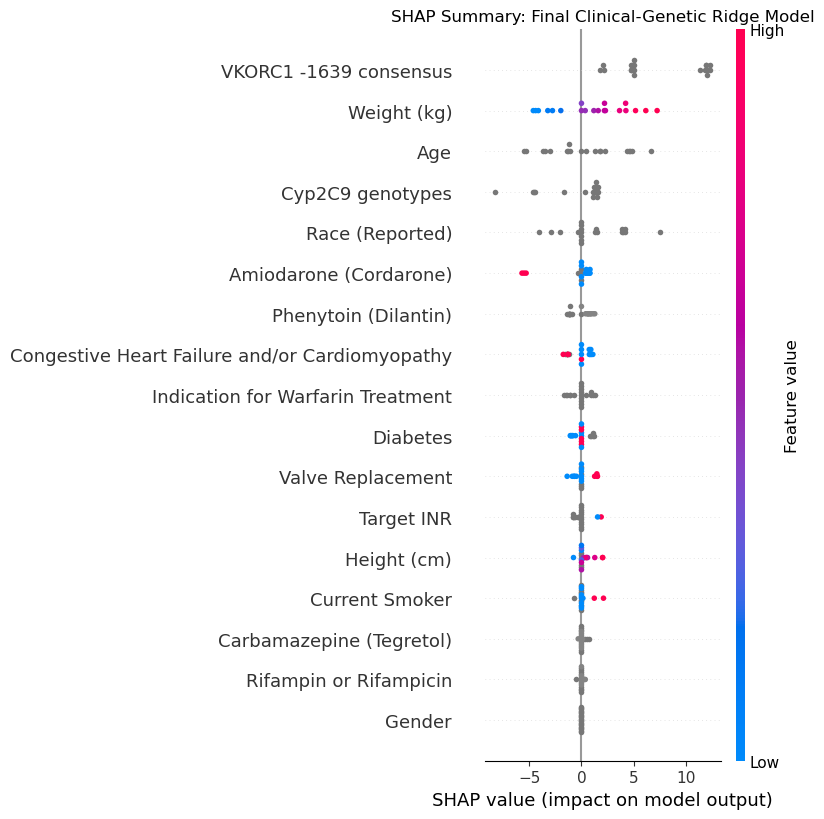

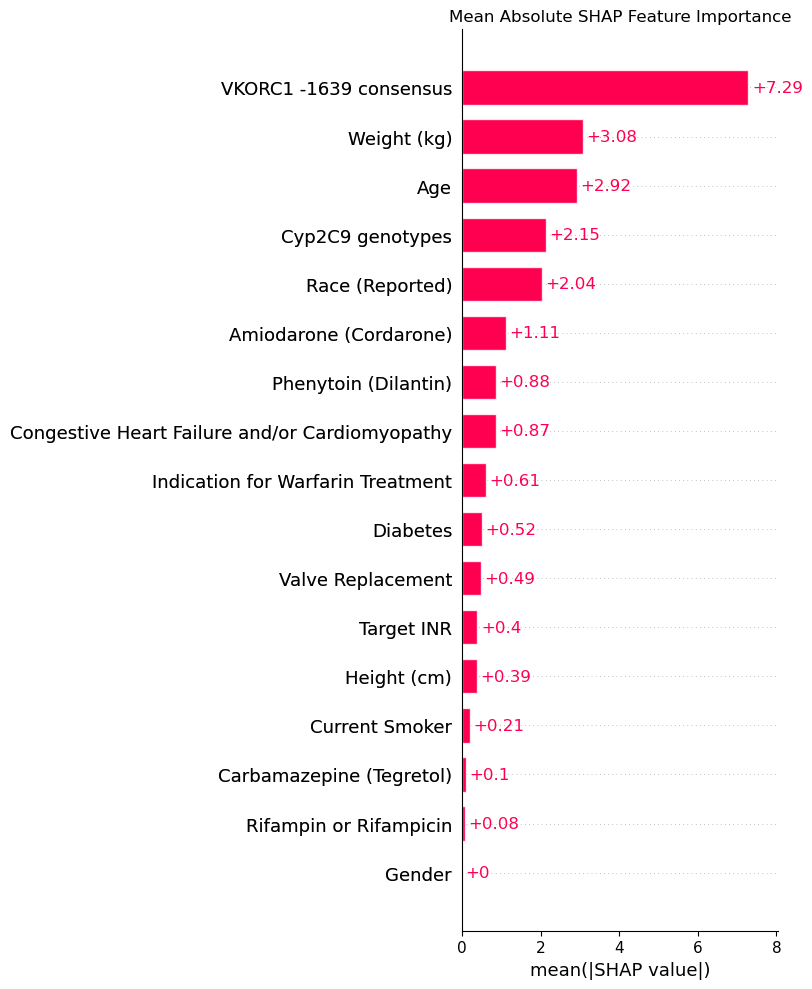

,Feature,Mean absolute SHAP value
0,VKORC1 -1639 consensus,7.288458
1,Weight (kg),3.082489
2,Age,2.921304
3,Cyp2C9 genotypes,2.147623
4,Race (Reported),2.044624
5,Amiodarone (Cordarone),1.110088
6,Phenytoin (Dilantin),0.875221
7,Congestive Heart Failure and/or Cardiomyopathy,0.869906
8,Indication for Warfarin Treatment,0.605345
9,Diabetes,0.518913


In [8]:
plt.figure()
shap.plots.beeswarm(
    shap_values,
    max_display=len(feature_names),
    show=False
)
plt.title("SHAP Summary: Final Clinical-Genetic Ridge Model")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "shap_summary_beeswarm.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure()
shap.plots.bar(
    shap_values,
    max_display=len(feature_names),
    show=False
)
plt.title("Mean Absolute SHAP Feature Importance")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "shap_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

global_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean absolute SHAP value": np.abs(shap_values_array).mean(axis=0)
}).sort_values("Mean absolute SHAP value", ascending=False).reset_index(drop=True)

display(global_importance)
global_importance.to_csv(
    os.path.join(OUTPUT_DIR, "shap_feature_importance.csv"),
    index=False
)

## 7. Local SHAP explanation

The waterfall plot explains one held-out test prediction. Positive SHAP values move the prediction above the SHAP baseline; negative SHAP values move it below the baseline.

The actual recorded dose is shown for transparency. The difference between the prediction and the recorded dose is a prediction error, not a treatment recommendation.

Test record index: 2623
Actual recorded dose (mg/week): 50.0
Model prediction (mg/week): 29.652
Prediction error (mg/week): -20.348
SHAP baseline (mg/week): 29.953


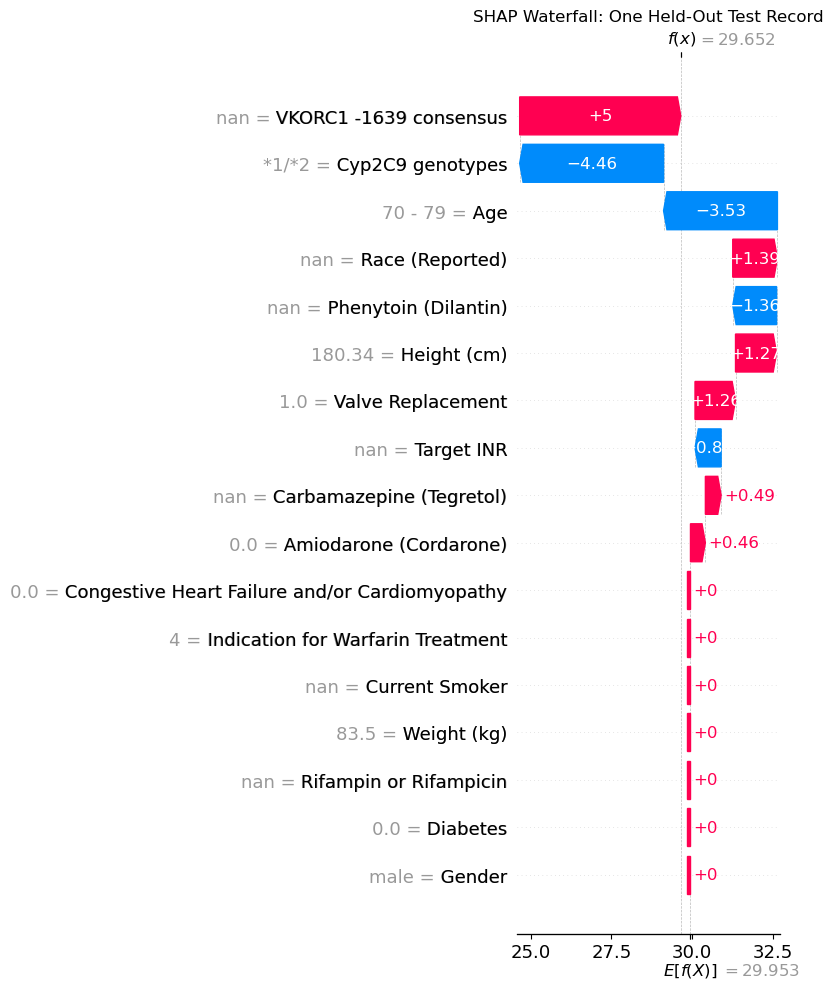

,Feature,Feature value,SHAP value,Absolute SHAP value
0,VKORC1 -1639 consensus,NaN,4.998661,4.998661
1,Cyp2C9 genotypes,*1/*2,-4.464705,4.464705
2,Age,70 - 79,-3.532742,3.532742
3,Race (Reported),NaN,1.386584,1.386584
4,Phenytoin (Dilantin),NaN,-1.361151,1.361151
5,Height (cm),180.34,1.274614,1.274614
6,Valve Replacement,1.0,1.256983,1.256983
7,Target INR,NaN,-0.810497,0.810497
8,Carbamazepine (Tegretol),NaN,0.488896,0.488896
9,Amiodarone (Cordarone),0.0,0.462268,0.462268


In [9]:
example_index = 0
example_row = X_explain_raw.iloc[[example_index]]

actual_dose = float(y.loc[example_row.index[0]])
predicted_dose = float(explained_pipeline.predict(example_row)[0])
prediction_error = predicted_dose - actual_dose

print("Test record index:", example_row.index[0])
print("Actual recorded dose (mg/week):", round(actual_dose, 3))
print("Model prediction (mg/week):", round(predicted_dose, 3))
print("Prediction error (mg/week):", round(prediction_error, 3))
print("SHAP baseline (mg/week):", round(float(shap_values.base_values[example_index]), 3))

plt.figure()
shap.plots.waterfall(
    shap_values[example_index],
    max_display=len(feature_names),
    show=False
)
plt.title("SHAP Waterfall: One Held-Out Test Record")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "shap_local_waterfall.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

local_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Feature value": [example_row.iloc[0][feature] for feature in feature_names],
    "SHAP value": shap_values_array[example_index],
    "Absolute SHAP value": np.abs(shap_values_array[example_index])
}).sort_values("Absolute SHAP value", ascending=False).reset_index(drop=True)

display(local_explanation)
local_explanation.to_csv(
    os.path.join(OUTPUT_DIR, "shap_local_explanation.csv"),
    index=False
)

## 8. Template-based natural-language generation

This component converts SHAP contributions into readable English sentences. It is a rule-based template NLG function, not a trained language model.

For each explained record, the function:

1. Combines feature names, patient feature values, and SHAP values.
2. Ranks features by absolute SHAP contribution.
3. Selects the top five contributing features.
4. Describes positive, negative, and near-zero contributions.
5. Includes the predicted dose and a research-only disclaimer.

The generated text describes the fitted model's behaviour. It does not state that a feature caused a change in the patient's required dose.

In [10]:
NEAR_ZERO_THRESHOLD = 0.10

def explain_with_nlp(feature_names, shap_values_for_record, example_row, predicted_dose):
    contributions = pd.DataFrame({
        "Feature": feature_names,
        "Feature value": [example_row.iloc[0][feature] for feature in feature_names],
        "SHAP value": np.asarray(shap_values_for_record)
    })

    contributions["Absolute SHAP value"] = contributions["SHAP value"].abs()
    contributions = contributions.sort_values(
        "Absolute SHAP value", ascending=False
    ).reset_index(drop=True)

    top_features = contributions.head(5)
    sentences = []

    sentences.append(
        f"The model predicted a weekly warfarin dose of "
        f"{predicted_dose:.3f} mg/week based on the provided patient information."
    )

    positive_features = top_features[top_features["SHAP value"] > NEAR_ZERO_THRESHOLD]
    negative_features = top_features[top_features["SHAP value"] < -NEAR_ZERO_THRESHOLD]
    near_zero_features = top_features[
        (top_features["SHAP value"] >= -NEAR_ZERO_THRESHOLD) &
        (top_features["SHAP value"] <= NEAR_ZERO_THRESHOLD)
    ]

    if len(positive_features) > 0:
        names = ", ".join(positive_features["Feature"].tolist())
        sentences.append(
            f"The following features contributed positively to the model prediction: {names}."
        )

    if len(negative_features) > 0:
        names = ", ".join(negative_features["Feature"].tolist())
        sentences.append(
            f"The following features contributed negatively to the model prediction: {names}."
        )

    if len(near_zero_features) > 0:
        names = ", ".join(near_zero_features["Feature"].tolist())
        sentences.append(
            f"The following features had little apparent contribution to this prediction: {names}."
        )

    if len(top_features) > 0:
        top_feature = top_features.iloc[0]
        sentences.append(
            f"The feature with the largest absolute SHAP contribution was "
            f"{top_feature['Feature']} (SHAP value: {top_feature['SHAP value']:.3f})."
        )

    sentences.append(
        "These statements describe the fitted model's behaviour and do not establish "
        "causation or provide medical advice. This prediction is not a replacement "
        "for professional clinical judgment."
    )

    explanation = " ".join(sentences)

    tokens = re.findall(r"\b[a-zA-Z0-9]+\b", explanation.lower())

    print("NLP GENERATED EXPLANATION:\n")
    print(explanation)
    print("\nNLP WORD TOKENS:\n")
    print(tokens)

    return explanation, contributions, tokens

nlp_explanation, nlp_contributions, nlp_tokens = explain_with_nlp(
    feature_names,
    shap_values_array[example_index],
    example_row,
    predicted_dose
)

nlp_contributions.to_csv(
    os.path.join(OUTPUT_DIR, "nlp_shap_explanation.csv"),
    index=False
)

with open(os.path.join(OUTPUT_DIR, "nlp_explanation.txt"), "w", encoding="utf-8") as file:
    file.write(nlp_explanation)

NLP GENERATED EXPLANATION:

The model predicted a weekly warfarin dose of 29.652 mg/week based on the provided patient information. The following features contributed positively to the model prediction: VKORC1 -1639 consensus, Race (Reported). The following features contributed negatively to the model prediction: Cyp2C9 genotypes, Age, Phenytoin (Dilantin). The feature with the largest absolute SHAP contribution was VKORC1 -1639 consensus (SHAP value: 4.999). These statements describe the fitted model's behaviour and do not establish causation or provide medical advice. This prediction is not a replacement for professional clinical judgment.

NLP WORD TOKENS:

['the', 'model', 'predicted', 'a', 'weekly', 'warfarin', 'dose', 'of', '29', '652', 'mg', 'week', 'based', 'on', 'the', 'provided', 'patient', 'information', 'the', 'following', 'features', 'contributed', 'positively', 'to', 'the', 'model', 'prediction', 'vkorc1', '1639', 'consensus', 'race', 'reported', 'the', 'following', 'feat

## 9. Generate explanations for all explained test records

This section generates a template-based explanation for every one of the 20 explained test records and saves the results in a CSV file. The explanations remain descriptive model explanations and must not be used for real treatment decisions.

In [12]:
all_nlp_explanations = []

for record_number in range(len(X_explain_raw)):
    row = X_explain_raw.iloc[[record_number]]
    prediction = float(explained_pipeline.predict(row)[0])
    explanation, contributions, tokens = explain_with_nlp(
        feature_names,
        shap_values_array[record_number],
        row,
        prediction
    )

    all_nlp_explanations.append({
        "Test record index": row.index[0],
        "Actual dose (mg/week)": float(y.loc[row.index[0]]),
        "Predicted dose (mg/week)": prediction,
        "Prediction error (mg/week)": prediction - float(y.loc[row.index[0]]),
        "Generated explanation": explanation
    })

nlp_all_df = pd.DataFrame(all_nlp_explanations)
display(nlp_all_df)

nlp_all_df.to_csv(
    os.path.join(OUTPUT_DIR, "nlp_shap_explanations_all_records.csv"),
    index=False
)

NLP GENERATED EXPLANATION:

The model predicted a weekly warfarin dose of 29.652 mg/week based on the provided patient information. The following features contributed positively to the model prediction: VKORC1 -1639 consensus, Race (Reported). The following features contributed negatively to the model prediction: Cyp2C9 genotypes, Age, Phenytoin (Dilantin). The feature with the largest absolute SHAP contribution was VKORC1 -1639 consensus (SHAP value: 4.999). These statements describe the fitted model's behaviour and do not establish causation or provide medical advice. This prediction is not a replacement for professional clinical judgment.

NLP WORD TOKENS:

['the', 'model', 'predicted', 'a', 'weekly', 'warfarin', 'dose', 'of', '29', '652', 'mg', 'week', 'based', 'on', 'the', 'provided', 'patient', 'information', 'the', 'following', 'features', 'contributed', 'positively', 'to', 'the', 'model', 'prediction', 'vkorc1', '1639', 'consensus', 'race', 'reported', 'the', 'following', 'feat

,Test record index,Actual dose (mg/week),Predicted dose (mg/week),Prediction error (mg/week),Generated explanation
0,2623,50.00,29.652295,-20.347705,The model predicted a weekly warfarin dose of ...
1,3223,80.01,49.393340,-30.616660,The model predicted a weekly warfarin dose of ...
2,3304,45.99,50.735272,4.745272,The model predicted a weekly warfarin dose of ...
3,4696,35.00,41.645029,6.645029,The model predicted a weekly warfarin dose of ...
4,2525,40.00,38.364792,-1.635208,The model predicted a weekly warfarin dose of ...
5,1526,17.50,27.293130,9.793130,The model predicted a weekly warfarin dose of ...
6,3524,27.00,30.109986,3.109986,The model predicted a weekly warfarin dose of ...
7,4712,28.00,31.130113,3.130113,The model predicted a weekly warfarin dose of ...
8,5604,20.02,25.092084,5.072084,The model predicted a weekly warfarin dose of ...
9,3496,52.50,53.615267,1.115267,The model predicted a weekly warfarin dose of ...


## 10. Save prediction and SHAP outputs

The following files are saved in `xai_results/`:

- `final_model_comparison.csv`
- `shap_summary_beeswarm.png`
- `shap_feature_importance.png`
- `shap_feature_importance.csv`
- `shap_local_waterfall.png`
- `shap_local_explanation.csv`
- `shap_additivity_check.csv`
- `nlp_shap_explanation.csv`
- `nlp_explanation.txt`
- `nlp_shap_explanations_all_records.csv`
- `XAI_NLP_Report.docx`

In [11]:
shap_values_dataframe = pd.DataFrame(
    shap_values_array,
    columns=feature_names
)
shap_values_dataframe.to_csv(
    os.path.join(OUTPUT_DIR, "shap_values.csv"),
    index=False
)

prediction_table = pd.DataFrame({
    "Test record index": X_explain_raw.index,
    "Actual dose (mg/week)": y.loc[X_explain_raw.index].values,
    "Predicted dose (mg/week)": explained_pipeline.predict(X_explain_raw),
    "Prediction error (mg/week)": (
        explained_pipeline.predict(X_explain_raw)
        - y.loc[X_explain_raw.index].values
    )
})

prediction_table.to_csv(
    os.path.join(OUTPUT_DIR, "shap_prediction_table.csv"),
    index=False
)

display(prediction_table)

,Test record index,Actual dose (mg/week),Predicted dose (mg/week),Prediction error (mg/week)
0,2623,50.00,29.652295,-20.347705
1,3223,80.01,49.393340,-30.616660
2,3304,45.99,50.735272,4.745272
3,4696,35.00,41.645029,6.645029
4,2525,40.00,38.364792,-1.635208
5,1526,17.50,27.293130,9.793130
6,3524,27.00,30.109986,3.109986
7,4712,28.00,31.130113,3.130113
8,5604,20.02,25.092084,5.072084
9,3496,52.50,53.615267,1.115267


In [13]:
import shutil

desktop_path = os.path.join(os.path.expanduser("~"), "Desktop")
destination = os.path.join(desktop_path, "WARFARIN_XAI_NLP_RESULTS")

shutil.copytree(OUTPUT_DIR, destination, dirs_exist_ok=True)
print("All results copied to:", destination)

All results copied to: C:\Users\Mirani\Desktop\WARFARIN_XAI_NLP_RESULTS
